### Simulation

Pharmaceutical Pricing Game Theory Simulation
-------------------------------------------
This simulation models the competitive bidding process between pharmaceutical companies.
Company F has a cost advantage and chooses between blocking or profitability strategies.

Choose simulation mode:
1. Static example (demonstrates both strategies)
2. Interactive simulation (adjust parameters)


Enter your choice (1 or 2):  1



Simulation Results (k=2.0 - Blocking Strategy Range):
Company F: Price=17.90, Strategy=Blocking, Profit=253.59
Company K: Price=19.80, Strategy=Cost-plus, Profit=-3.21
Company W: Price=22.00, Strategy=Cost-plus, Profit=0.00
Winning Price: 17.90


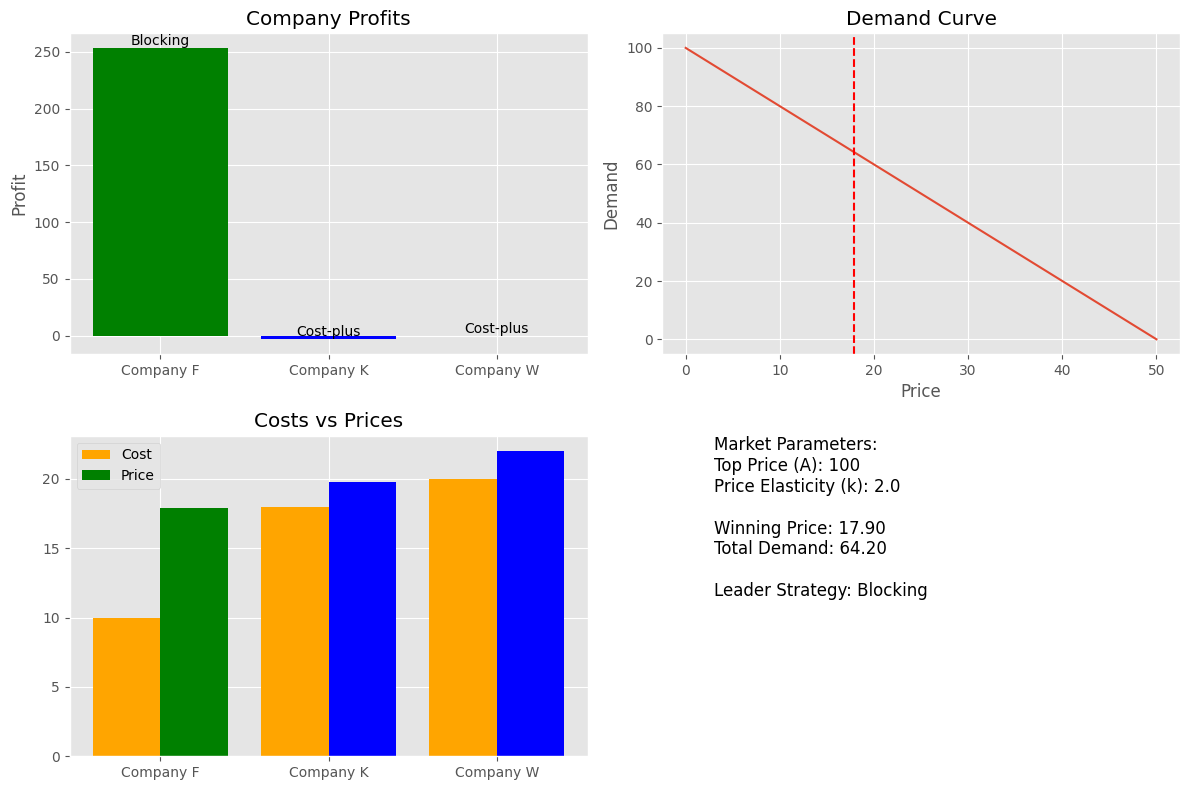


Simulation Results (k=3.0 - Profitability Strategy Range):
Company F: Price=21.67, Strategy=Profitability, Profit=198.94
Company K: Price=19.80, Strategy=Cost-plus, Profit=36.54
Company W: Price=22.00, Strategy=Cost-plus, Profit=0.00
Winning Price: 19.80


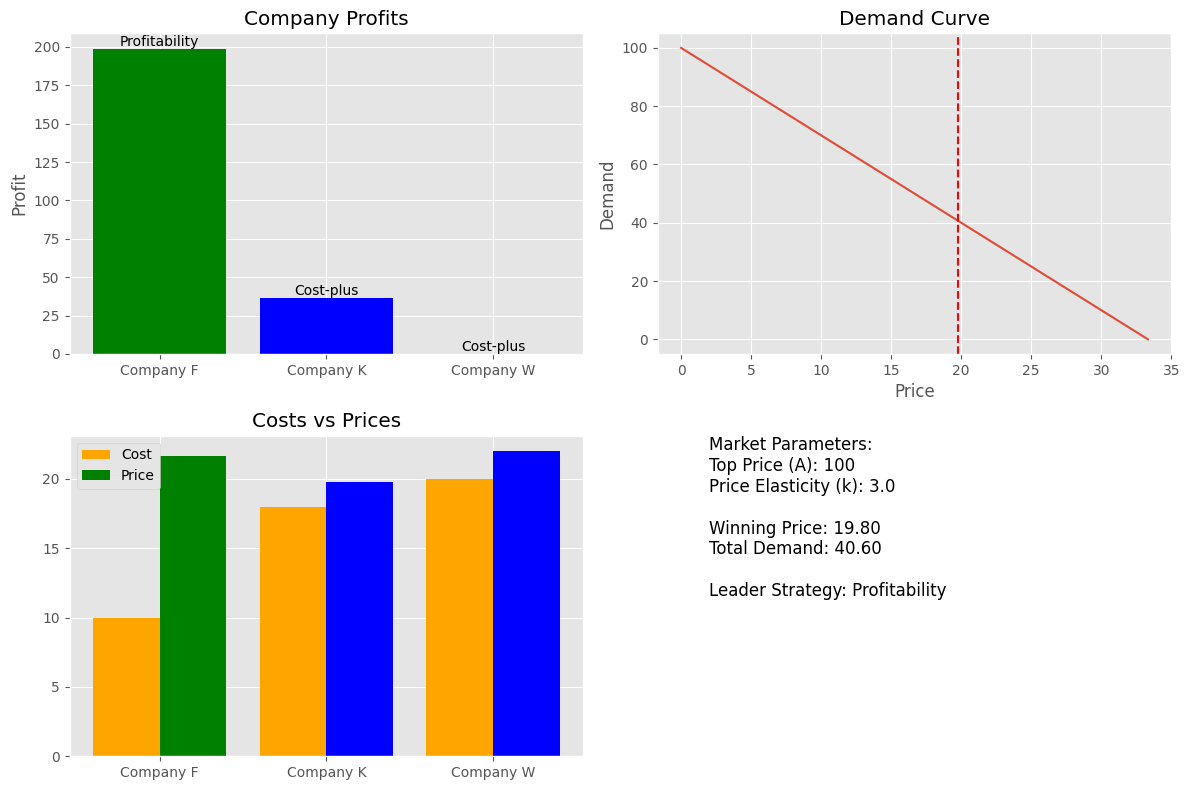

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.widgets import Slider

class PharmaceuticalCompany:
    def __init__(self, name, cost, is_leader=False):
        self.name = name
        self.cost = cost  # Unit production cost
        self.is_leader = is_leader  # Whether this company has cost advantage
        self.price = None
        self.profit = 0
        self.strategy = None
    
    def set_price(self, price):
        self.price = price
    
    def calculate_profit(self, winning_price, market_share, demand_function):
        if self.price == winning_price or (self.price > winning_price and np.random.random() < 0.3):  # 30% chance to accept higher price
            quantity = market_share * demand_function(winning_price)
            self.profit = (winning_price - self.cost) * quantity
            return True  # Company wins the bid
        return False  # Company loses the bid

def demand_function(price, A=100, k=2):
    """Inverse demand function: Q = A - k*P"""
    return max(0, A - k * price)

def run_simulation(companies, A=100, k=2):
    # Each company sets its price based on its strategy
    for company in companies:
        if company.is_leader:
            # Leader company (cost advantage) uses optimal pricing strategy
            if 1.7 <= k <= 2.5:
                # Low-price blocking strategy (slightly under competitor's cost)
                competitor_costs = [c.cost for c in companies if not c.is_leader]
                company.set_price(min(competitor_costs) - 0.1)
                company.strategy = "Blocking"
            else:
                # High-price profitability strategy (Nash equilibrium)
                company.set_price((A + k * company.cost) / (2 * k))
                company.strategy = "Profitability"
        else:
            # Follower companies set price at their cost plus small margin
            company.set_price(company.cost * 1.1)
            company.strategy = "Cost-plus"
    
    # Find winning price (lowest price)
    prices = [c.price for c in companies]
    winning_price = min(prices)
    winning_companies = [c for c in companies if c.price == winning_price]
    
    # Determine market share based on number of winners
    if len(winning_companies) == 1:
        market_share = 0.5  # 50% market share for single winner
    elif len(winning_companies) == 2:
        market_share = 0.3  # 30% each for two winners (60% total)
    else:
        market_share = 0.233  # ~23.3% each for three winners (70% total)
    
    # Calculate profits
    for company in companies:
        company.calculate_profit(winning_price, market_share, lambda p: demand_function(p, A, k))
    
    return companies, winning_price

def plot_results(companies, winning_price, A, k):
    plt.figure(figsize=(12, 8))
    
    # Plot company profits
    names = [c.name for c in companies]
    profits = [c.profit for c in companies]
    strategies = [c.strategy for c in companies]
    
    colors = ['green' if c.is_leader else 'blue' for c in companies]
    
    plt.subplot(2, 2, 1)
    bars = plt.bar(names, profits, color=colors)
    plt.title('Company Profits')
    plt.ylabel('Profit')
    
    # Add strategy annotations
    for bar, strategy in zip(bars, strategies):
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2., height,
                 strategy,
                 ha='center', va='bottom')
    
    # Plot demand curve
    plt.subplot(2, 2, 2)
    prices = np.linspace(0, A/k, 100)
    demands = [demand_function(p, A, k) for p in prices]
    plt.plot(prices, demands)
    plt.axvline(x=winning_price, color='r', linestyle='--')
    plt.title('Demand Curve')
    plt.xlabel('Price')
    plt.ylabel('Demand')
    plt.grid(True)
    
    # Plot company costs and prices
    plt.subplot(2, 2, 3)
    costs = [c.cost for c in companies]
    prices = [c.price for c in companies]
    x = range(len(companies))
    
    plt.bar(x, costs, width=0.4, label='Cost', color='orange')
    plt.bar([i + 0.4 for i in x], prices, width=0.4, label='Price', color=colors)
    plt.xticks([i + 0.2 for i in x], names)
    plt.title('Costs vs Prices')
    plt.legend()
    
    # Add text summary
    plt.subplot(2, 2, 4)
    plt.axis('off')
    summary_text = (
        f"Market Parameters:\n"
        f"Top Price (A): {A}\n"
        f"Price Elasticity (k): {k:.1f}\n\n"
        f"Winning Price: {winning_price:.2f}\n"
        f"Total Demand: {demand_function(winning_price, A, k):.2f}\n\n"
        f"Leader Strategy: {[c.strategy for c in companies if c.is_leader][0]}"
    )
    plt.text(0.1, 0.5, summary_text, fontsize=12)
    
    plt.tight_layout()
    plt.show()

def interactive_simulation():
    # Create companies
    company_F = PharmaceuticalCompany("Company F", 10, is_leader=True)
    company_K = PharmaceuticalCompany("Company K", 18)
    company_W = PharmaceuticalCompany("Company W", 20)
    companies = [company_F, company_K, company_W]
    
    # Set up figure and sliders
    fig, ax = plt.subplots(figsize=(10, 6))
    plt.subplots_adjust(bottom=0.3)
    
    ax_A = plt.axes([0.25, 0.2, 0.65, 0.03])
    ax_k = plt.axes([0.25, 0.15, 0.65, 0.03])
    
    slider_A = Slider(ax_A, 'Top Price (A)', 50, 150, valinit=100)
    slider_k = Slider(ax_k, 'Elasticity (k)', 0.5, 5, valinit=2)
    
    def update(val):
        A = slider_A.val
        k = slider_k.val
        
        # Run simulation with current parameters
        updated_companies, winning_price = run_simulation(companies, A, k)
        
        # Clear and redraw
        ax.clear()
        
        # Plot updated results
        names = [c.name for c in updated_companies]
        profits = [c.profit for c in updated_companies]
        strategies = [c.strategy for c in updated_companies]
        colors = ['green' if c.is_leader else 'blue' for c in updated_companies]
        
        bars = ax.bar(names, profits, color=colors)
        ax.set_title(f'Pharmaceutical Pricing Game (A={A}, k={k:.1f})')
        ax.set_ylabel('Profit')
        ax.grid(True)
        
        # Add strategy annotations
        for bar, strategy in zip(bars, strategies):
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height,
                     f"{strategy}\n{height:.0f}",
                     ha='center', va='bottom')
        
        # Add winning price info
        ax.text(0.5, 0.9, f"Winning Price: {winning_price:.2f}",
                transform=ax.transAxes, ha='center')
        
        fig.canvas.draw_idle()
    
    slider_A.on_changed(update)
    slider_k.on_changed(update)
    
    # Initial update
    update(None)
    
    plt.show()

# Run a static simulation example
def static_simulation_example():
    # Create companies - F has cost advantage
    company_F = PharmaceuticalCompany("Company F", 10, is_leader=True)
    company_K = PharmaceuticalCompany("Company K", 18)
    company_W = PharmaceuticalCompany("Company W", 20)
    
    # Run simulation with k=2 (within the 1.7-2.5 range for blocking strategy)
    results, winning_price = run_simulation([company_F, company_K, company_W], A=100, k=2)
    
    # Display results
    print("\nSimulation Results (k=2.0 - Blocking Strategy Range):")
    for company in results:
        print(f"{company.name}: Price={company.price:.2f}, Strategy={company.strategy}, Profit={company.profit:.2f}")
    print(f"Winning Price: {winning_price:.2f}")
    
    # Plot results
    plot_results(results, winning_price, A=100, k=2)
    
    # Run simulation with k=3 (outside blocking strategy range)
    results, winning_price = run_simulation([company_F, company_K, company_W], A=100, k=3)
    
    # Display results
    print("\nSimulation Results (k=3.0 - Profitability Strategy Range):")
    for company in results:
        print(f"{company.name}: Price={company.price:.2f}, Strategy={company.strategy}, Profit={company.profit:.2f}")
    print(f"Winning Price: {winning_price:.2f}")
    
    # Plot results
    plot_results(results, winning_price, A=100, k=3)

# Run either the interactive or static simulation
if __name__ == "__main__":
    print("Pharmaceutical Pricing Game Theory Simulation")
    print("-------------------------------------------")
    print("This simulation models the competitive bidding process between pharmaceutical companies.")
    print("Company F has a cost advantage and chooses between blocking or profitability strategies.")
    print("\nChoose simulation mode:")
    print("1. Static example (demonstrates both strategies)")
    print("2. Interactive simulation (adjust parameters)")
    
    choice = input("Enter your choice (1 or 2): ")
    
    if choice == "1":
        static_simulation_example()
    elif choice == "2":
        interactive_simulation()
    else:
        print("Invalid choice. Running static example.")
        static_simulation_example()

### Enhancement

Enhanced Pharmaceutical Pricing Game Theory Simulation
----------------------------------------------------
This simulation models competitive bidding between pharmaceutical companies.
Key features:
- Leader company (F) uses game theory strategies (blocking vs profitability)
- Follower companies use adaptive pricing strategies
- Market dynamics with demand fluctuations
- Multi-round simulations with historical tracking
- Interactive parameter adjustment


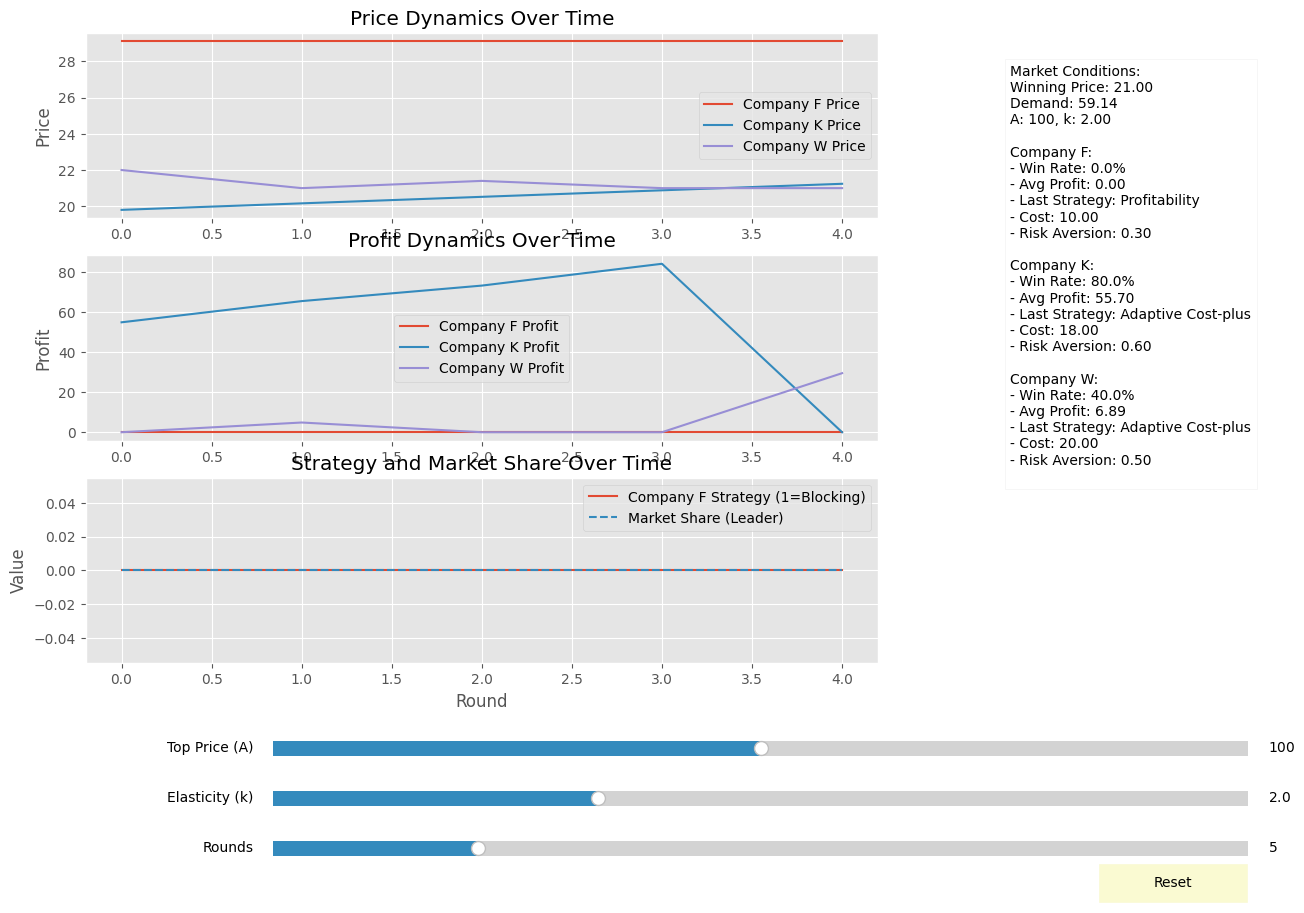

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.widgets import Slider, Button
import matplotlib.gridspec as gridspec
from collections import defaultdict

class PharmaceuticalCompany:
    def __init__(self, name, cost, is_leader=False, risk_aversion=0.5):
        self.name = name
        self.cost = cost  # Unit production cost
        self.is_leader = is_leader
        self.risk_aversion = risk_aversion  # 0-1 where 1 is very risk averse
        self.price_history = []
        self.profit_history = []
        self.strategy_history = []
        self.market_share_history = []
        
    def set_price(self, price):
        self.price_history.append(price)
        
    def calculate_profit(self, winning_price, market_share, demand):
        if (self.price_history[-1] == winning_price or 
            (self.price_history[-1] > winning_price and np.random.random() < (1 - self.risk_aversion)/2)):
            quantity = market_share * demand
            profit = (winning_price - self.cost) * quantity
            self.profit_history.append(profit)
            self.market_share_history.append(market_share)
            return True
        self.profit_history.append(0)
        self.market_share_history.append(0)
        return False
    
    def decide_strategy(self, A, k, competitors):
        if not self.is_leader:
            # Followers use adaptive cost-plus pricing
            last_profit = self.profit_history[-1] if self.profit_history else 0
            if last_profit == 0:  # Lost last bid
                margin = max(0.05, (self.price_history[-1] - self.cost)/self.cost - 0.05) if self.price_history else 0.1
            else:
                margin = min(0.3, (self.price_history[-1] - self.cost)/self.cost + 0.02)
            price = self.cost * (1 + margin)
            strategy = "Adaptive Cost-plus"
        else:
            # Leader uses game theory strategies
            competitor_costs = [c.cost for c in competitors if not c.is_leader]
            avg_competitor_cost = np.mean(competitor_costs)
            
            # Calculate strategy thresholds based on paper's propositions
            F = 2/15 - (2/5)*0.5 + (1/2)*0.5**2  # Example probability combination
            threshold1 = (k*(k + 2*self.cost) - A + k*np.sqrt((A - k*self.cost)**2 + F))/(2*k)
            threshold2 = (k*(k + 2*self.cost) - A - k*np.sqrt((A - k*self.cost)**2 + F))/(2*k)
            
            if threshold1 < avg_competitor_cost <= threshold2:
                # Low-price blocking strategy
                price = min(competitor_costs) * (1 - 0.05 * (1 + self.risk_aversion))
                strategy = "Blocking"
            else:
                # High-price profitability strategy (Nash equilibrium)
                price = (A + k * self.cost) / (2 * k)
                # Adjust for risk aversion
                price = price * (1 - 0.1 * self.risk_aversion)
                strategy = "Profitability"
        
        self.set_price(price)
        self.strategy_history.append(strategy)
        return strategy

def demand_function(price, A, k):
    """Inverse demand function with random fluctuation"""
    base_demand = max(0, A - k * price)
    # Add small random fluctuation (5% variation)
    return base_demand * (1 + (np.random.random() - 0.5) * 0.05)

def run_simulation(companies, A, k, rounds=1):
    history = defaultdict(list)
    
    for _ in range(rounds):
        # Companies decide their strategies and prices
        for company in companies:
            company.decide_strategy(A, k, companies)
        
        # Find winning price (lowest price)
        current_prices = [c.price_history[-1] for c in companies]
        winning_price = min(current_prices)
        winning_companies = [c for c in companies if c.price_history[-1] == winning_price]
        
        # Determine market share based on number of winners
        if len(winning_companies) == 1:
            market_share = 0.5  # 50% market share for single winner
        elif len(winning_companies) == 2:
            market_share = 0.3  # 30% each for two winners (60% total)
        else:
            market_share = 0.233  # ~23.3% each for three winners (70% total)
        
        # Calculate demand
        current_demand = demand_function(winning_price, A, k)
        
        # Calculate profits and record results
        for company in companies:
            wins_bid = company.calculate_profit(winning_price, market_share, current_demand)
            history[company.name].append({
                'price': company.price_history[-1],
                'profit': company.profit_history[-1],
                'strategy': company.strategy_history[-1],
                'wins_bid': wins_bid,
                'market_share': company.market_share_history[-1]
            })
        
        history['market'].append({
            'winning_price': winning_price,
            'demand': current_demand,
            'A': A,
            'k': k
        })
    
    return history

def plot_results(history, companies):
    plt.figure(figsize=(15, 10))
    gs = gridspec.GridSpec(3, 2, width_ratios=[3, 1])
    
    # Plot price and profit history
    ax1 = plt.subplot(gs[0, 0])
    for company in companies:
        prices = [h['price'] for h in history[company.name]]
        ax1.plot(prices, label=f'{company.name} Price', linestyle='-')
    ax1.set_title('Price Dynamics Over Time')
    ax1.set_ylabel('Price')
    ax1.legend()
    ax1.grid(True)
    
    ax2 = plt.subplot(gs[1, 0])
    for company in companies:
        profits = [h['profit'] for h in history[company.name]]
        ax2.plot(profits, label=f'{company.name} Profit', linestyle='-')
    ax2.set_title('Profit Dynamics Over Time')
    ax2.set_ylabel('Profit')
    ax2.legend()
    ax2.grid(True)
    
    # Plot strategy and market share
    ax3 = plt.subplot(gs[2, 0])
    for company in companies:
        if company.is_leader:
            strategies = [1 if h['strategy'] == 'Blocking' else 0 for h in history[company.name]]
            ax3.plot(strategies, label=f'{company.name} Strategy (1=Blocking)', linestyle='-')
    market_shares = [h['market_share'] for h in history[companies[0].name]]
    ax3.plot(market_shares, label='Market Share (Leader)', linestyle='--')
    ax3.set_title('Strategy and Market Share Over Time')
    ax3.set_xlabel('Round')
    ax3.set_ylabel('Value')
    ax3.legend()
    ax3.grid(True)
    
    # Summary statistics
    ax4 = plt.subplot(gs[:, 1])
    ax4.axis('off')
    
    summary_text = []
    market = history['market'][-1]
    summary_text.append(f"Final Market Conditions:")
    summary_text.append(f"Winning Price: {market['winning_price']:.2f}")
    summary_text.append(f"Demand: {market['demand']:.2f}")
    summary_text.append(f"A: {market['A']}, k: {market['k']:.2f}\n")
    
    for company in companies:
        company_history = history[company.name]
        wins = sum(1 for h in company_history if h['wins_bid'])
        avg_profit = np.mean([h['profit'] for h in company_history])
        last_strategy = company_history[-1]['strategy']
        
        summary_text.append(f"{company.name}:")
        summary_text.append(f"- Win Rate: {wins/len(company_history):.1%}")
        summary_text.append(f"- Avg Profit: {avg_profit:.2f}")
        summary_text.append(f"- Last Strategy: {last_strategy}")
        summary_text.append(f"- Cost: {company.cost:.2f}")
        summary_text.append(f"- Risk Aversion: {company.risk_aversion:.2f}\n")
    
    ax4.text(0.1, 0.95, "\n".join(summary_text), fontsize=10, 
             verticalalignment='top', bbox=dict(facecolor='white', alpha=0.7))
    
    plt.tight_layout()
    plt.show()

def interactive_simulation():
    # Create companies with different risk profiles
    company_F = PharmaceuticalCompany("Company F", 10, is_leader=True, risk_aversion=0.3)
    company_K = PharmaceuticalCompany("Company K", 18, risk_aversion=0.6)
    company_W = PharmaceuticalCompany("Company W", 20, risk_aversion=0.5)
    companies = [company_F, company_K, company_W]
    
    # Set up figure and sliders
    fig = plt.figure(figsize=(15, 10))
    gs = gridspec.GridSpec(3, 2, width_ratios=[3, 1])
    
    # Create axes for plots
    ax1 = plt.subplot(gs[0, 0])
    ax2 = plt.subplot(gs[1, 0])
    ax3 = plt.subplot(gs[2, 0])
    ax4 = plt.subplot(gs[:, 1])
    
    plt.subplots_adjust(bottom=0.25)
    
    # Create slider axes
    ax_A = plt.axes([0.25, 0.15, 0.65, 0.03])
    ax_k = plt.axes([0.25, 0.10, 0.65, 0.03])
    ax_rounds = plt.axes([0.25, 0.05, 0.65, 0.03])
    
    slider_A = Slider(ax_A, 'Top Price (A)', 50, 150, valinit=100)
    slider_k = Slider(ax_k, 'Elasticity (k)', 0.5, 5, valinit=2)
    slider_rounds = Slider(ax_rounds, 'Rounds', 1, 20, valinit=5, valstep=1)
    
    # Add reset button
    reset_ax = plt.axes([0.8, 0.01, 0.1, 0.04])
    reset_button = Button(reset_ax, 'Reset', color='lightgoldenrodyellow', hovercolor='0.975')
    
    def reset(event):
        slider_A.reset()
        slider_k.reset()
        slider_rounds.reset()
    
    reset_button.on_clicked(reset)
    
    def update(val):
        A = slider_A.val
        k = slider_k.val
        rounds = int(slider_rounds.val)
        
        # Reset company histories
        for company in companies:
            company.price_history = []
            company.profit_history = []
            company.strategy_history = []
            company.market_share_history = []
        
        # Run simulation
        history = run_simulation(companies, A, k, rounds)
        
        # Clear and redraw
        for ax in [ax1, ax2, ax3, ax4]:
            ax.clear()
            ax.grid(True)
        
        # Plot price history
        for company in companies:
            prices = [h['price'] for h in history[company.name]]
            ax1.plot(prices, label=f'{company.name} Price', linestyle='-')
        ax1.set_title('Price Dynamics Over Time')
        ax1.set_ylabel('Price')
        ax1.legend()
        
        # Plot profit history
        for company in companies:
            profits = [h['profit'] for h in history[company.name]]
            ax2.plot(profits, label=f'{company.name} Profit', linestyle='-')
        ax2.set_title('Profit Dynamics Over Time')
        ax2.set_ylabel('Profit')
        ax2.legend()
        
        # Plot strategy and market share
        for company in companies:
            if company.is_leader:
                strategies = [1 if h['strategy'] == 'Blocking' else 0 for h in history[company.name]]
                ax3.plot(strategies, label=f'{company.name} Strategy (1=Blocking)', linestyle='-')
        market_shares = [h['market_share'] for h in history[companies[0].name]]
        ax3.plot(market_shares, label='Market Share (Leader)', linestyle='--')
        ax3.set_title('Strategy and Market Share Over Time')
        ax3.set_xlabel('Round')
        ax3.set_ylabel('Value')
        ax3.legend()
        
        # Summary statistics
        ax4.axis('off')
        
        summary_text = []
        market = history['market'][-1]
        summary_text.append(f"Market Conditions:")
        summary_text.append(f"Winning Price: {market['winning_price']:.2f}")
        summary_text.append(f"Demand: {market['demand']:.2f}")
        summary_text.append(f"A: {market['A']}, k: {market['k']:.2f}\n")
        
        for company in companies:
            company_history = history[company.name]
            wins = sum(1 for h in company_history if h['wins_bid'])
            avg_profit = np.mean([h['profit'] for h in company_history])
            last_strategy = company_history[-1]['strategy']
            
            summary_text.append(f"{company.name}:")
            summary_text.append(f"- Win Rate: {wins/len(company_history):.1%}")
            summary_text.append(f"- Avg Profit: {avg_profit:.2f}")
            summary_text.append(f"- Last Strategy: {last_strategy}")
            summary_text.append(f"- Cost: {company.cost:.2f}")
            summary_text.append(f"- Risk Aversion: {company.risk_aversion:.2f}\n")
        
        ax4.text(0.1, 0.95, "\n".join(summary_text), fontsize=10, 
                 verticalalignment='top', bbox=dict(facecolor='white', alpha=0.7))
        
        fig.canvas.draw_idle()
    
    slider_A.on_changed(update)
    slider_k.on_changed(update)
    slider_rounds.on_changed(update)
    
    # Initial update
    update(None)
    
    plt.show()

def main():
    print("Enhanced Pharmaceutical Pricing Game Theory Simulation")
    print("----------------------------------------------------")
    print("This simulation models competitive bidding between pharmaceutical companies.")
    print("Key features:")
    print("- Leader company (F) uses game theory strategies (blocking vs profitability)")
    print("- Follower companies use adaptive pricing strategies")
    print("- Market dynamics with demand fluctuations")
    print("- Multi-round simulations with historical tracking")
    print("- Interactive parameter adjustment")
    
    interactive_simulation()

if __name__ == "__main__":
    main()